<a href="https://colab.research.google.com/github/victorealeal/pressao-hospitalar-sns/blob/main/03_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise: pressão hospitalar no SNS
Notebook 03: análise da tabela limpa de ocupação e urgência (2022-2026).

## Perguntas
1. **Ocupação:** a taxa de ocupação mudou entre 2022 e 2026, e tem padrão sazonal? (usa só as linhas com taxa confiável)
2. **Urgência:** que proporção dos atendimentos é de baixa gravidade (pulseiras verde e azul)? A cor branca é analisada à parte, porque não faz parte do sistema de Manchester e, segundo fontes jornalísticas, indica atendimentos por razões administrativas ou casos clínicos específicos.
3. **Relação:** as instituições com mais atendimentos na urgência são também as mais ocupadas?

Caso de estudo: a região do Algarve, onde a análise de 2026 usa os dias de internamento em vez da taxa.

In [3]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

tabela = pd.read_csv('/content/drive/MyDrive/semantix/dados_limpos.csv', parse_dates=['periodo'])
tabela.shape

Mounted at /content/drive


(2471, 16)

## Pergunta 1: evolução e sazonalidade da ocupação
Taxa de ocupação mensal mediana entre as instituições, usando apenas as linhas com taxa confiável. Foi usada a mediana, e não a média, para que valores extremos de poucas instituições não distorçam o resultado.

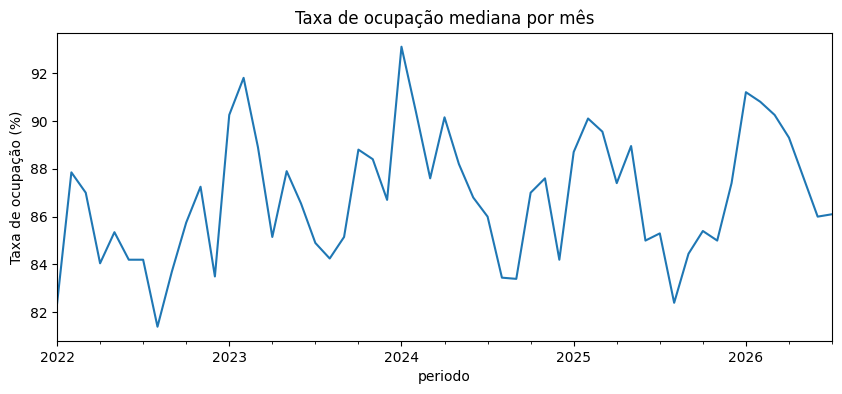

In [4]:
mediana_mes = tabela[tabela['taxa_fiavel']].groupby('periodo')['taxa_mes'].median()

ax = mediana_mes.plot(figsize=(10, 4), title='Taxa de ocupação mediana por mês')
ax.set_ylabel('Taxa de ocupação (%)');

,taxa_mes
mes,
1,88.8
2,89.7
3,88.3
4,86.9
5,87.4
6,85.4
7,85.4
8,82.5
9,84.3


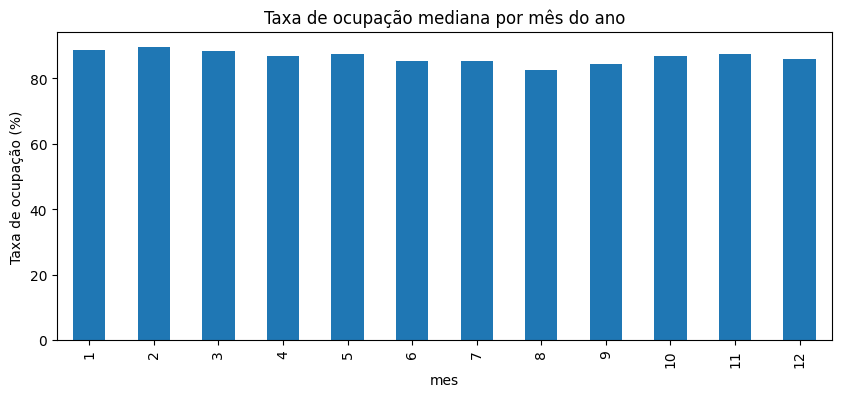

In [5]:
sazonal = tabela[tabela['taxa_fiavel']].groupby('mes')['taxa_mes'].median().round(1)

ax = sazonal.plot(kind='bar', figsize=(10, 4), title='Taxa de ocupação mediana por mês do ano')
ax.set_ylabel('Taxa de ocupação (%)');
sazonal

**Conclusões da pergunta 1**

- A taxa de ocupação mediana oscila entre cerca de 81% e 93% e não mostra tendência de subida ou descida entre 2022 e 2026.
- Há sazonalidade clara: os valores mais altos ocorrem no inverno (fevereiro 89,7%, janeiro 88,8%) e em outubro (88,7%), e o mais baixo em agosto (82,5%), uma diferença de cerca de 7 pontos percentuais.
- Não se observa um degrau em janeiro de 2024, apesar da reorganização das instituições, já que todos os inícios de ano têm pico.
- Limitações: é a mediana entre instituições (cada uma pesa o mesmo), usa apenas linhas com taxa confiável, e os meses de agosto a dezembro têm 4 anos de dados contra 5 nos restantes.

## Pergunta 2: proporção de atendimentos de baixa gravidade
Proporção de atendimentos com pulseira verde ou azul sobre o total triado nas cinco cores de Manchester. A cor branca e os atendimentos sem triagem ficam fora do cálculo.

In [6]:
cores = ['vermelha', 'laranja', 'amarela', 'verde', 'azul']

urgencia = tabela.dropna(subset=cores).copy()
urgencia['triados'] = urgencia[cores].sum(axis=1)

# Distribuição por cor, em todo o período
total = urgencia[cores].sum()
print((total / total.sum() * 100).round(1))

vermelha     0.4
laranja     11.1
amarela     50.5
verde       36.5
azul         1.5
dtype: float64


In [7]:
por_ano = urgencia.groupby('ano')[['verde', 'azul', 'triados']].sum()
(por_ano['verde'] + por_ano['azul']) / por_ano['triados'] * 100

,0
ano,
2022,42.853401
2023,40.110782
2024,38.774365
2025,33.279130
2026,32.311153


In [8]:
jan_jul = urgencia[urgencia['mes'] <= 7].groupby('ano')[['verde', 'azul', 'triados']].sum()
(jan_jul['verde'] + jan_jul['azul']) / jan_jul['triados'] * 100

,0
ano,
2022,43.329097
2023,40.333091
2024,39.325248
2025,33.564769
2026,32.311153


**Conclusões da pergunta 2**

- No conjunto de 2022 a 2026, 38,0% dos atendimentos triados nas urgências têm pulseira verde (36,5%) ou azul (1,5%), isto é, são pouco ou não urgentes. A amarela representa metade (50,5%), a laranja 11,1% e a vermelha 0,4%.
- A proporção de verde e azul diminui de 42,9% em 2022 para 40,1% em 2023, 38,8% em 2024 e 33,3% em 2025, uma queda de cerca de 10 pontos percentuais. Em 2026 (janeiro a julho) é de 32,3%.
- Os valores são coerentes com o reportado pela imprensa a partir do mesmo portal (cerca de 40% em 2018).
- Limitações: proporção ponderada pelo volume (hospitais maiores pesam mais); a cor branca e os atendimentos sem triagem ficam fora; os dados mostram a evolução, mas não as causas;
- A comparação restrita a janeiro-julho de cada ano mantém a mesma queda, o que indica que ela não resulta de 2026 ter apenas sete meses.


## Pergunta 3: relação entre urgência e ocupação
Para cada instituição, comparação entre a média mensal de atendimentos triados (cinco cores de Manchester) e a taxa de ocupação mediana, usando apenas linhas com taxa confiável e urgência completa. Foi usada a correlação de Spearman, que não se deixa distorcer por valores extremos.

In [9]:
tabela['triados'] = tabela[cores].sum(axis=1, min_count=5)
ok = tabela[tabela['taxa_fiavel'] & tabela['triados'].notna()]

por_inst = ok.groupby('instituicao').agg(
    urgencia_media=('triados', 'mean'),
    ocupacao_mediana=('taxa_mes', 'median'))

print(len(por_inst), 'instituições')
por_inst.corr(method='spearman')

40 instituições


,urgencia_media,ocupacao_mediana
urgencia_media,1.00000,0.28054
ocupacao_mediana,0.28054,1.00000


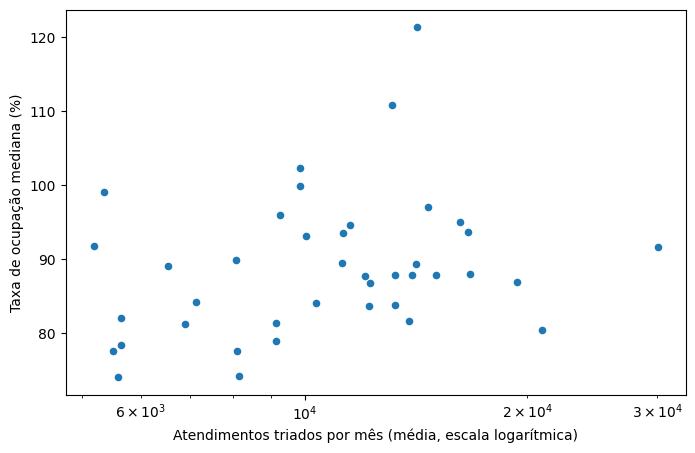

In [10]:
ax = por_inst.plot.scatter(x='urgencia_media', y='ocupacao_mediana', logx=True, figsize=(8, 5))
ax.set_xlabel('Atendimentos triados por mês (média, escala logarítmica)')
ax.set_ylabel('Taxa de ocupação mediana (%)');

**Conclusões da pergunta 3**

- Entre as 40 instituições, a correlação de Spearman entre a média mensal de atendimentos triados e a taxa de ocupação mediana é de 0,28: uma relação positiva, mas fraca.
- No gráfico, os pontos não formam um padrão claro: há instituições com muita urgência e ocupação baixa, e o maior serviço de urgência tem ocupação intermédia (cerca de 91%).
- Com apenas 40 instituições, uma correlação desta dimensão pode ocorrer por acaso (estimativa aproximada: cerca de 8%), por isso não se conclui que a relação exista.
- Limitações: a taxa de ocupação depende da lotação registada, e algumas instituições têm taxa mediana acima de 100%; a correlação não indica causa; instituições maiores têm mais atendimentos por dimensão.

## Caso de estudo: Algarve
A ULS do Algarve é analisada com os dias de internamento e os atendimentos triados, e não com a taxa de ocupação, porque a lotação registada muda de cerca de 920 para 329 camas em janeiro de 2026.

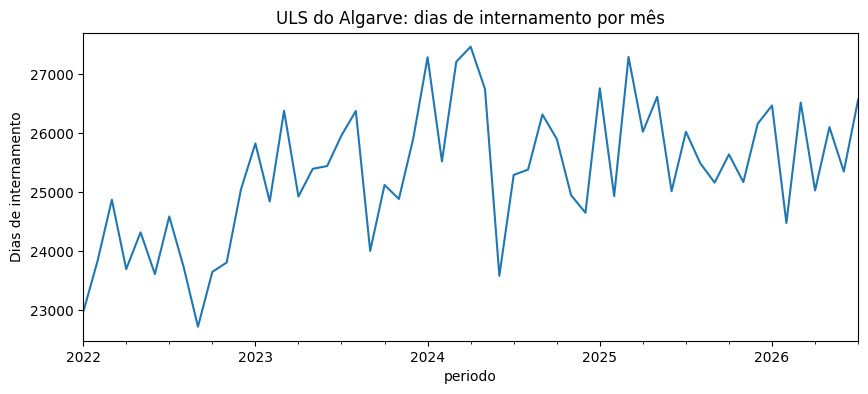

In [11]:
alg = tabela[tabela['instituicao'].str.contains('Algarve')]

ax = alg.set_index('periodo')['dias_mes'].plot(figsize=(10, 4), title='ULS do Algarve: dias de internamento por mês')
ax.set_ylabel('Dias de internamento');

In [12]:
alg[alg['mes'] <= 7].groupby('ano')[['dias_mes', 'triados']].sum()

,dias_mes,triados
ano,,
2022,167896.0,202610.0
2023,178781.0,208028.0
2024,183107.0,212738.0
2025,182667.0,206607.0
2026,180520.0,200969.0


**Conclusões do caso do Algarve**

- Os dias de internamento mensais da ULS do Algarve subiram durante 2022 e 2023 e, desde então, oscilam entre cerca de 24 mil e 27 mil, sem tendência clara. Não se observa pico no verão.
- Comparando janeiro-julho de cada ano, os dias de internamento passam de 167.896 (2022) para 183.107 (2024), um aumento de cerca de 9%, e ficam estáveis depois (180.520 em 2026). O maior aumento ocorre entre 2022 e 2023, antes da reorganização de 2024.
- Os atendimentos triados na urgência sobem até 2024 (212.738) e descem em 2025 e 2026 (200.969, ligeiramente abaixo de 2022).
- Em 2025, com cerca de 900 camas registadas, a taxa de ocupação mensal ficou entre 91% e 97%, acima da mediana geral (86,7%). Para 2026 a taxa não é confiável, e não é possível afirmar se a pressão aumentou ou diminuiu.
- Limitações: o aumento de 2022 para 2023 pode refletir atividade real ou mudanças no registo; os dados não permitem distinguir.

## Conclusões do notebook 03

- **Ocupação:** a taxa mediana oscila entre 81% e 93%, sem tendência entre 2022 e 2026, com sazonalidade clara: máxima em fevereiro (89,7%) e mínima em agosto (82,5%).
- **Urgência:** 38,0% dos atendimentos têm pulseira verde ou azul, e esta proporção cai de 42,9% (2022) para 33,3% (2025) e 32,3% (2026, janeiro-julho).
- **Relação entre as duas:** a correlação entre urgência e ocupação por instituição é fraca (0,28) e pode dever-se ao acaso.
- **Algarve:** dias de internamento estáveis desde 2023; urgência a descer desde 2024; a ocupação de 2026 não pode ser avaliada pela taxa.
- **Limitações:** dados agregados por instituição e mês (padrões, não causas); correspondência de nomes validada pelos dados e não por fonte oficial; vazios da urgência e a cor branca com significado por confirmar.

*Próximo passo:* consultas em SQL e painel em Power BI (a seguir no curso) e o README do projeto.